# Analysis — Many Particles

## Configuração
Edite apenas esta célula para adicionar/remover partículas ou frequências.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
np.seterr('warn')

from treament_tcspc_data import fetch_data_filenames, extract_data_info_from_path, get_xf_yf_fund, get_mean_amp_and_phase, get_fft, time_domain_visual_verification
from snr_aux_functions import get_snr_db, plot_time_and_freq_domain

In [2]:
filenames_all = sorted(fetch_data_filenames("./experimental_data/"))

In [3]:
# filenames_all = fetch_data_filenames("./23-05-26")
exc_data_npy = [
    extract_data_info_from_path(data_path_npy) for data_path_npy in filenames_all 
    if ("step" in data_path_npy) and (".npy" in data_path_npy) and ("exc_laser" in data_path_npy)
    ]

In [4]:
#Populate particle list

num_particles = 1
p_list = [
    {
        "p_label": p_id+1,
        "p_data": [
            extract_data_info_from_path(p_data_path)
            for p_data_path in filenames_all
            if (f"p{p_id+1}_lum" in p_data_path) and ("step" in p_data_path) and (".npy" in p_data_path)
        ]
    }
    for p_id in range(num_particles)
]

In [5]:
nice_blue = "#0ba4eb"

## Análise — loop sobre N partículas

### Plot all


  Processing particle 1  


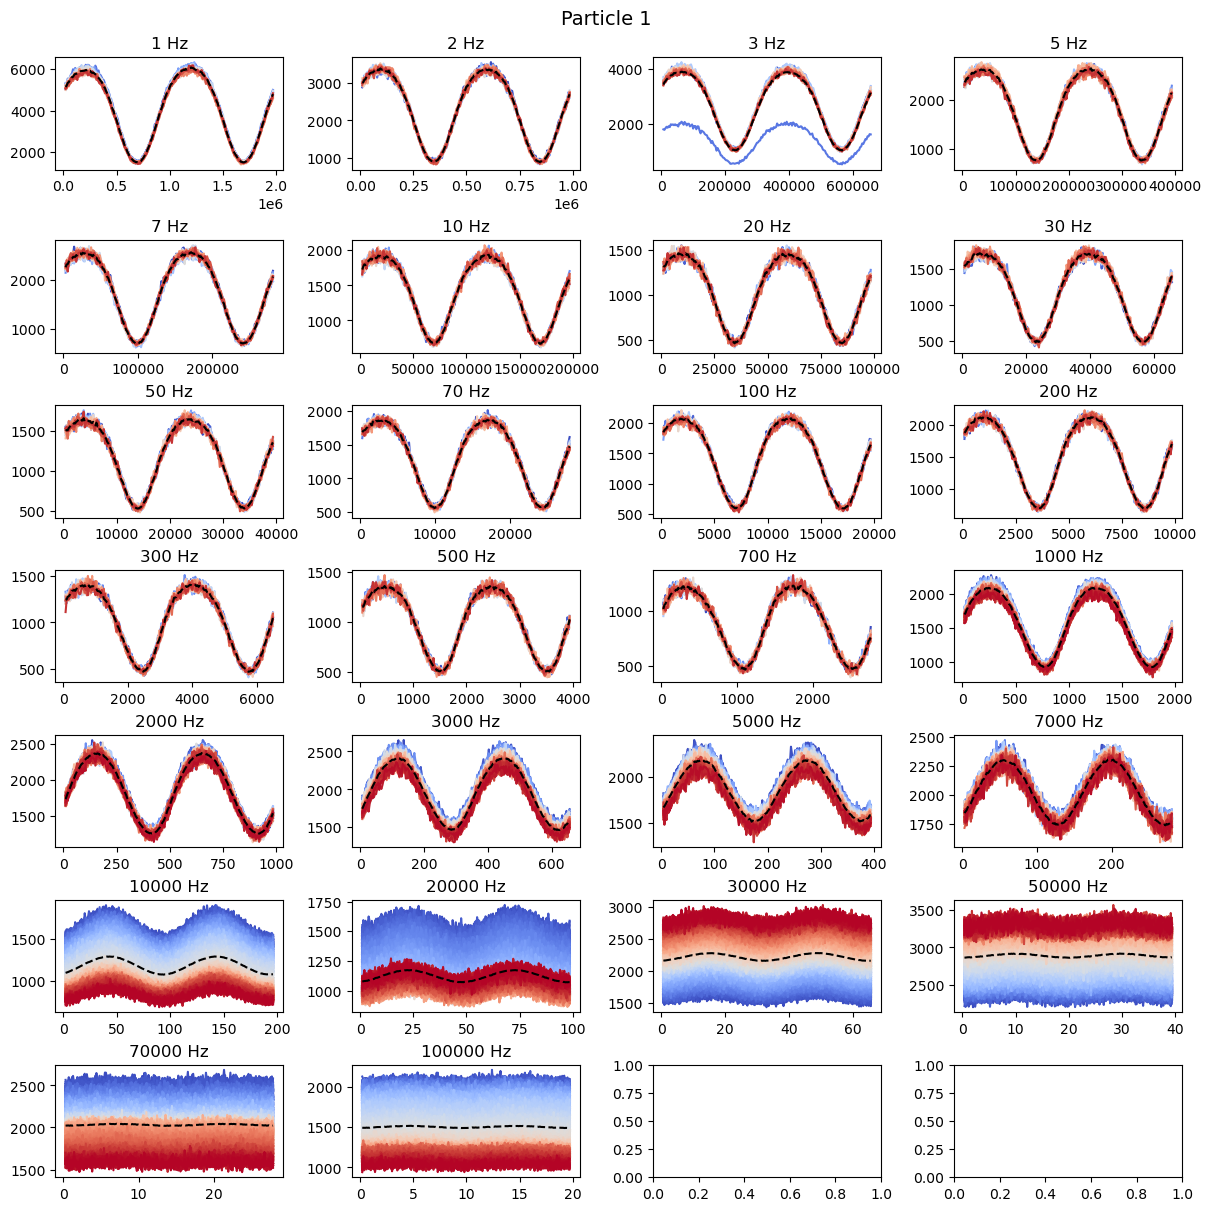

In [6]:
time_domain_visual_verification(p_list,
                                particles_off=[i for i in range(num_particles) if (i != 1) and (i != 0) ], 
                                show_mean=True
                                )


  Processing particle 2  


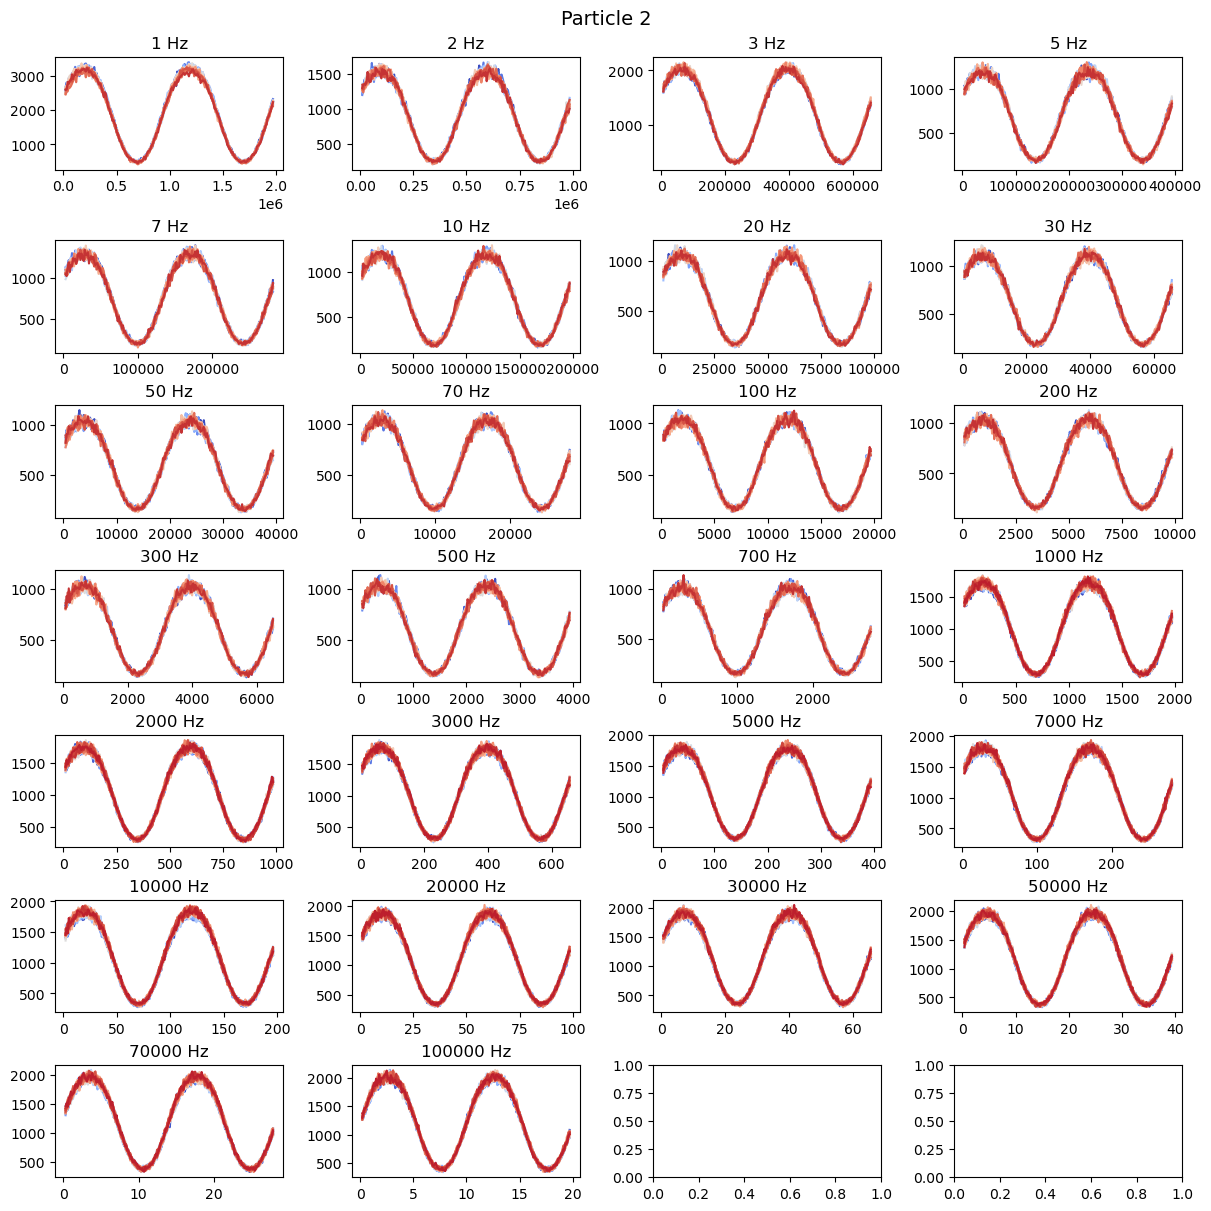

In [7]:
## Excitation
time_domain_visual_verification(
    [
        {
            "p_label": 2,
            "p_data": exc_data_npy
        }
    ]
)

## Get mean phases and errors

In [8]:
#Calculate list of phasors for the laser and all measurements
for step in exc_data_npy:
  freq = step["freq"]
  step["fft_amp_list"] = []
  for meas_idx, meas in enumerate(step["data"]):
    _, amp = get_xf_yf_fund(meas[:,0], meas[:,1], freq)
    step["fft_amp_list"].append(amp)

In [9]:
# Get mean phase and error for each particle and each step (freq) 
for step in exc_data_npy:
    freq = step["freq"]
    amp_list = step["fft_amp_list"]
    _, _, phase, phase_error = get_mean_amp_and_phase(amp_list)
    step["mean_fft_info"] = [freq, phase, phase_error]

In [10]:
#Calculate list of phasors for all particles and all measurements
for p in p_list:
  for step in p["p_data"]:
    freq = step["freq"]
    step["fft_amp_list"] = []
    for meas_idx, meas in enumerate(step["data"]):
      _, amp = get_xf_yf_fund(meas[:,0], meas[:,1], freq)
      step["fft_amp_list"].append(amp)

In [11]:
# Get mean phase and error for each particle and each step (freq) 
for p in p_list:
    for step in p["p_data"]:
        freq = step["freq"]
        amp_list = step["fft_amp_list"]
        _, _, phase, phase_error = get_mean_amp_and_phase(amp_list)
        step["mean_fft_info"] = [freq, phase, phase_error]

## Comparison — all particles

In [12]:
def get_error_bar(exc_data, p_list):
    exc_mean_phase = np.array([
            step["mean_fft_info"]
            #[freq, phase, phase_error]
            for step in exc_data
        ])
    error_exc = exc_mean_phase[:,2]
    # print(error_exc)

    for p in p_list:
        # if p["p_label"] !=2: continue
        p_mean_phase = np.array([
            step["mean_fft_info"]
            for step in p["p_data"]
            ])
        
        if (p_mean_phase[:,0]-exc_mean_phase[:,0]).sum() != 0.:
            print("Deu ruim!")
            return None
        else:
            pd_list = np.unwrap(p_mean_phase[:,1]-exc_mean_phase[:,1])
            pd_error = np.hypot(
                p_mean_phase[:,2],
                exc_mean_phase[:,2]
            )

        p["error_bar"] = np.column_stack((p_mean_phase[:,0], pd_list, pd_error))

get_error_bar(exc_data_npy, p_list)

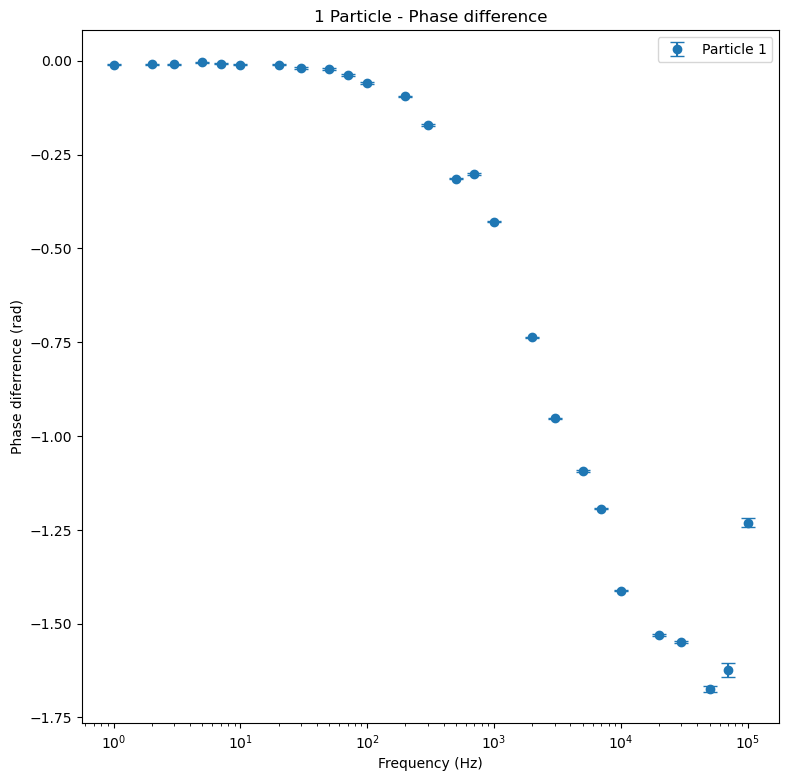

In [13]:
def plot_phase_difference(particles: list, p_to_skip = [], freqs_to_skip = []):
    plt.figure(figsize=(9, 9))

    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    for p_id, p in enumerate(particles):
        if p["p_label"] in p_to_skip: continue
        color = colors[p_id % len(colors)]
        # p["error_bar"]
        label_added = False
        for idx, error_point in enumerate(p["error_bar"]):
            # Skip frequencies larger than 20kHz
            if (error_point[0] in freqs_to_skip): 
                # print(f"Não foi calculado pra freq: {error_point[0]}Hz")
                continue
            
            current_label = f"Particle {p['p_label']}" if not label_added else None

            plt.errorbar(
                error_point[0],
                error_point[1],
                yerr=error_point[2],
                label=current_label,
                fmt='o',
                capsize=5,
                color=color,
            )
            label_added = True
        # plt.title(f"Particle {p['p_label']}  - phase difference")
        plt.xlabel("Frequency (Hz)")
        plt.ylabel("Phase diferrence (rad)")
        plt.xscale("log")
    
    if len(particles)>1:
        plt_title = f"{len(particles)} Particles - Phase difference" 
    else:
        plt_title = f"{len(particles)} Particle - Phase difference" 

    
    plt.title(plt_title)
    plt.legend()
    plt.show()

plot_phase_difference(p_list,
                    p_to_skip=[i for i in range(1, 31) if (i != 1) and (i != 2)],
                    freqs_to_skip=[]
                    )

## Modulus and phase of fundamental and 2n harmonic

### Laser analysis


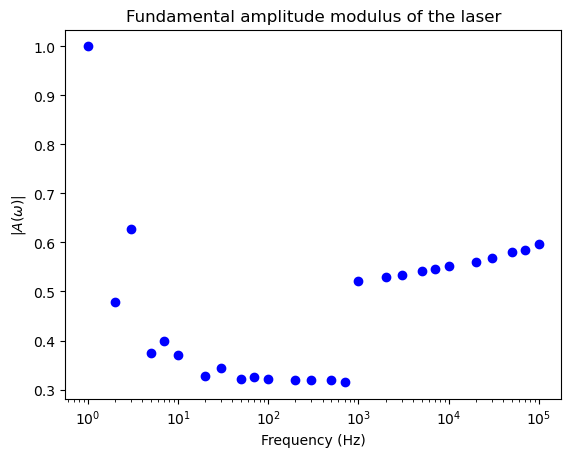

In [14]:
freq_list = []
mean_amp_list = []
for step in exc_data_npy:
    freq_list.append(step["freq"])
    mean_amp_list.append(np.mean(step["fft_amp_list"]))

freq_list = np.array(freq_list)
mean_amp_list = np.array(mean_amp_list)

plt.scatter(freq_list, np.abs(mean_amp_list)/np.abs(mean_amp_list).max(),
            color="blue")

plt.title("Fundamental amplitude modulus of the laser")

plt.ylabel("$|A(\omega)|$")
plt.xlabel("Frequency (Hz)")
plt.xscale("log")
plt.show()

A partir de 1kHz, o modo do TCSPC é GPTIM, mais eficiente e capaz de contar mais fótons. Por isso vemos uma variação abrupta nos pontos em torno de 1kHz.

### Luminescence analysis

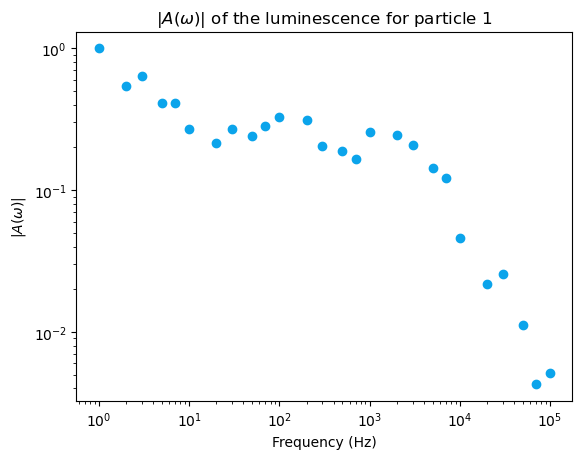

In [15]:
freq_list = []
mean_amp_list = []

for p in p_list:
    if p["p_label"] != 1: continue
    for step in p["p_data"]:
        freq_list.append(step["freq"])
        mean_amp_list.append(np.mean(step["fft_amp_list"]))

freq_list = np.array(freq_list)
mean_amp_list = np.array(mean_amp_list)

plt.scatter(freq_list, np.abs(mean_amp_list)/np.abs(mean_amp_list).max(), 
            color=nice_blue)

plt.title("$|A(\omega)|$ of the luminescence for particle " + f"{p["p_label"]}" )

plt.ylabel("$|A(\omega)|$")
plt.xlabel("Frequency (Hz)")
plt.xscale("log")
plt.yscale("log")
plt.show()

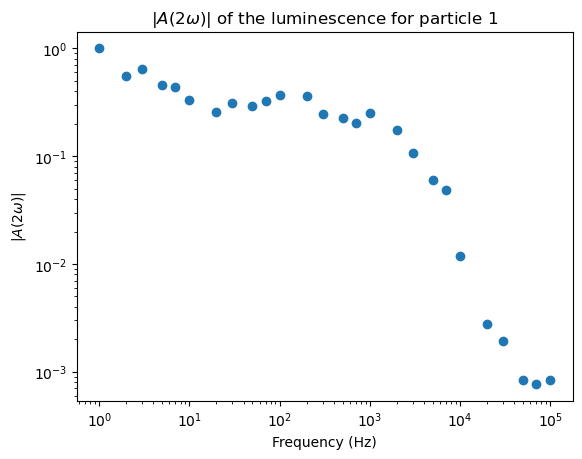

In [16]:
mean_amp2_list = []

for p in p_list:
    if p["p_label"] != 1: continue
    for step in p["p_data"]:
        freq = step["freq"]

        time = np.array(step["data"])[0,:,0]
        curve = np.array(step["data"])[:,:,1].mean(axis=0)

        _, yf_2omega = get_xf_yf_fund(time, curve, 2*freq)

        mean_amp2_list.append([
            freq, np.abs(yf_2omega)
        ])

    mean_amp2_list = np.array(mean_amp2_list)
    
    plt.scatter(mean_amp2_list[:,0], mean_amp2_list[:,1]/mean_amp2_list[:,1].max())
    plt.title("$|A(2\omega)|$ of the luminescence for particle " + f"{p["p_label"]}")
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("$|A(2\omega)|$")
    plt.show()

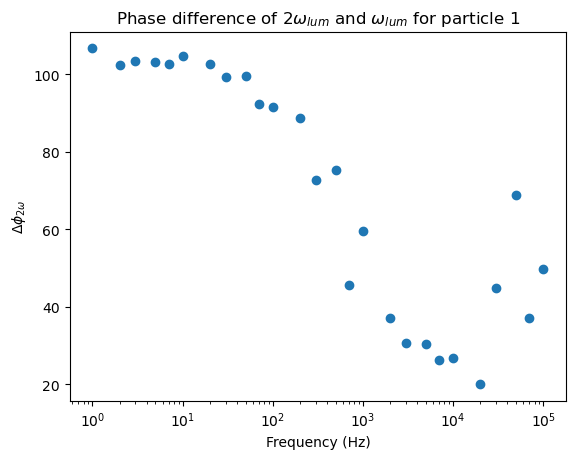

In [17]:
mean_phi2_list = []

for p in p_list:
    if p["p_label"] != 1: continue
    for step in p["p_data"]:
        # if step["freq"] != 20: continue
        freq = step["freq"]
        # print(f"freq = {freq}Hz")
        time = np.array(step["data"])[0,:,0]
        curve = np.array(step["data"])[:,:,1].mean(axis=0)

        _, yf = get_xf_yf_fund(time, curve, freq)
        _, yf_2omega = get_xf_yf_fund(time, curve, 2*freq)
        # _, yf_3omega = get_xf_yf_fund(time, curve, 3*freq)
        # print(type(yf))
        mean_phi2_list.append([
            freq, np.angle(yf_2omega) - np.angle(yf)
        ])

    mean_phi2_list = np.array(mean_phi2_list)
    
    plt.scatter(mean_phi2_list[:,0], np.degrees(np.unwrap(mean_phi2_list[:,1])))
    plt.title("Phase difference of $2\omega_{lum}$ and $\omega_{lum}$ for particle " + f"{p["p_label"]}")
    plt.xscale("log")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("$\Delta \phi_{2\omega}$")
    plt.show()

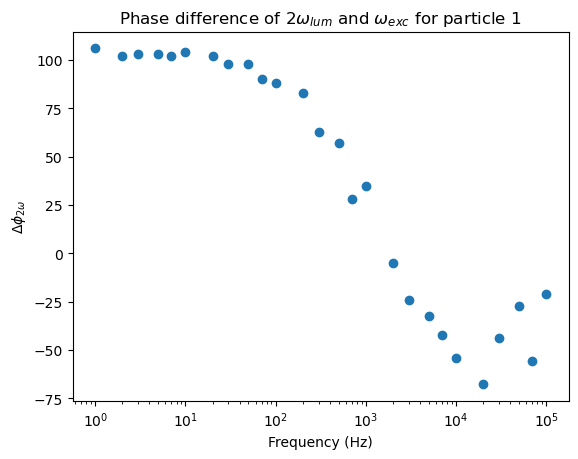

In [18]:
mean_phi2_list = []

for p in p_list:
    if p["p_label"] != 1: continue
    for step_idx, step in enumerate(p["p_data"]):
        # if step["freq"] != 20: continue
        freq = step["freq"]
        if exc_data_npy[step_idx]["freq"] != freq: raise IndexError("The excitation and luminescence indeces do not matching")

        mean_exc_amp = np.mean(exc_data_npy[step_idx]["fft_amp_list"])
        
        time = np.array(step["data"])[0,:,0]
        curve = np.array(step["data"])[:,:,1].mean(axis=0)

        # _, yf = get_xf_yf_fund(time, curve, freq)
        _, yf_2omega = get_xf_yf_fund(time, curve, 2*freq)

        mean_phi2_list.append([
            freq, np.angle(yf_2omega) - np.angle(mean_exc_amp)
        ])

    mean_phi2_list = np.array(mean_phi2_list)
    
    plt.scatter(mean_phi2_list[:,0], np.degrees(np.unwrap(mean_phi2_list[:,1])))
    plt.title("Phase difference of $2\omega_{lum}$ and $\omega_{exc}$ for particle " + f"{p["p_label"]}")
    plt.xscale("log")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("$\Delta \phi_{2\omega}$")
    plt.show()

